<a href="https://colab.research.google.com/github/simonpogo/AI/blob/main/grade_classifier_K_NN_vs_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Grade Classifier - napovedovanje ocen

Cilj naše naloge je preprost. Naučiti stroj, da iz podatka - odstotek (%) na testu pove oceno (1-5).

###Rešitev z algoritmom k-nearest neighbors (ne k-means)!

##Ključne značilnosti algoritma v  kodi:

Isti problem, kot smo ga imeli v beležnici grade_classifier_NN  se da rešiti z algoritmom *K-Nearest Neighbors (KNN)*, medtem ko K-Means za ta namen ni najbolj primeren.

1. K-Nearest Neighbors (KNN) — DA, je zelo primeren
KNN je algoritem za nadzorovano učenje (supervised learning) in se lahko neposredno uporabi za klasifikacijo ocen.
* Kako deluje?  Ko modelu podamo nov odstotek (npr. 72%), algoritem pogleda K najbližjih točk v učni množici (npr. tiste, ki imajo odstotke najbližje 72%) in dodeli oceno na podlagi večinskega glasovanja teh sosedov.

*  Prednosti: Izjemno preprost, ne potrebuje dolgotrajnega treniranja (uči se sproti ob iskanju sosedov) in bi pri enodimenzionalnem podatku (samo odstotek) deloval skoraj brez napake.
2. K-Means — NE, ni primeren (oziroma le z omejitvami)
K-Means je algoritem za *nenadzorovano učenje (unsupervised learning)*, katerega cilj je združevanje podatkov v skupine (gručenje ali clustering) brez vnaprejšnjih oznak (ocen).

###Zakaj ni primeren?
K-Means ne ve, kaj pomeni "ocena 1" ali "ocena 5". Podatke bi sicer lahko razdelil v 5 skupin (grup) glede na bližino odstotkov, vendar te skupine ne bi imele vnaprej določenega pomena.

Kdaj bi deloval: Deloval bi le, če bi po končanem gručenju ročno pregledal vsako skupino in ji določil oceno (npr. skupina z najnižjimi odstotki je ocena 1, naslednja je 2 itd.). Ker pa oznake (ocene) že imamo, je uporaba K-Means nesmiselna in manj natančna od nadzorovanih metod.

# POZOR!
## Prvih 5 celic je še vedno NN algoritem, ki sem ga pustil za primerjavo. Algoritem k-NN  se prične kasneje (scroll down)!

In [1]:
!pip -q install numpy pandas matplotlib seaborn statsmodels torch

In [2]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Uporabljena naprava: {device}")

Uporabljena naprava: cuda


## Nastavitve eksperimenta

Po potrebi spremeni vrednosti v naslednji celici. `training_percent` in `eval_percent` skupaj ne smeta presegati 100.

In [ ]:
data_rows = 1000
epoch_count = 1000
training_percent = 80
eval_percent = 10
learning_rate = 0.1
random_seed = 42

if training_percent + eval_percent >= 100:
    raise ValueError("Odstotka za treniranje in validacijo morata skupaj biti manjša od 100.")

random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

In [ ]:
def create_data(num_rows):
    percentages = np.round(np.random.random(num_rows) * 100, 1)
    grades = np.select(
        [percentages < 49, percentages < 62, percentages < 75, percentages < 89],
        [1, 2, 3, 4],
        default=5,
    )
    return pd.DataFrame({"percent": percentages, "grade": grades})

data = create_data(data_rows)
data.head()

,percent,grade
0,37.5,1
1,95.1,5
2,73.2,3
3,59.9,2
4,15.6,1


#Sprememba nevronske mreže
Iz preprostega linearnega modela (Linearna klasifikacija) sem prešel na model, ki ima eno skrito plast. Če želimo model povečati v smislu njegove zmogljivosti ali kompleksnosti (da bo imel več parametrov in bo lahko bolje napovedoval kompleksne vzorce), moramo narediti naslednje:

*Spremeniti arhitekturo modela v kodi:* Namesto enostavnega linearnega modela lahko ustvarimo večplastno nevronsko mrežo (z vmesnimi skritimi plastmi in aktivacijskimi funkcijami, npr. ReLU).
Model ponovno natrenirati: Model z novo arhitekturo moramo znova naučiti na podatkih.
Shraniti novo .pth datoteko: Po učenju shranimo nove uteži, ki bodo zaradi večje arhitekture zasedale več prostora (datoteka bo večja).

Primer, kako lahko v kodi povečaš model:
Trenutno uporabljaš zelo preprost model:

`model = nn.Linear(1, 5) # Samo 1 vhod in 5 izhodov (skupaj le 10 parametrov)`

Povečan model z vmesno skrito plastjo (npr. s 64 nevroni) bi izgledal takole:

```
model = nn.Sequential(
    nn.Linear(1, 64),   # Vhodna plast -> skrita plast s 64 nevroni
    nn.ReLU(),          # Aktivacijska funkcija za nelinearnost
    nn.Linear(64, 5)    # Skrita plast -> 5 izhodnih razredov
).to(device)
```

Tako povečan model bo imel bistveno več parametrov, njegova .pth datoteka bo večja, model pa bo sposoben prepoznati kompleksnejše meje med ocenami.

In [ ]:
X = torch.tensor(data[["percent"]].values, dtype=torch.float32, device=device) / 100.0
y = torch.tensor(data["grade"].values - 1, dtype=torch.long, device=device)

indices = torch.randperm(len(data), device=device)
train_size = int(training_percent / 100 * len(data))
val_size = int(eval_percent / 100 * len(data))
train_idx = indices[:train_size]
val_idx = indices[train_size:train_size + val_size]
test_idx = indices[train_size + val_size:]

# Povečan model s skrito plastjo
model = nn.Sequential(
    nn.Linear(1, 64),
    nn.ReLU(),
    nn.Linear(64, 5)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=learning_rate)
validation_losses = []
validation_accuracies = []

for epoch in range(epoch_count):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(X[train_idx]), y[train_idx])
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0 or epoch == 0:
        model.eval()
        with torch.no_grad():
            val_outputs = model(X[val_idx])
            val_loss = criterion(val_outputs, y[val_idx]).item()
            preds = val_outputs.argmax(dim=1)
            val_acc = (preds == y[val_idx]).float().mean().item() * 100

        validation_losses.append((epoch + 1, val_loss))
        validation_accuracies.append((epoch + 1, val_acc))
        print(f"Epoha {epoch + 1:>5} | Validacijski loss: {val_loss:.4f} | Točnost: {val_acc:.2f}%")

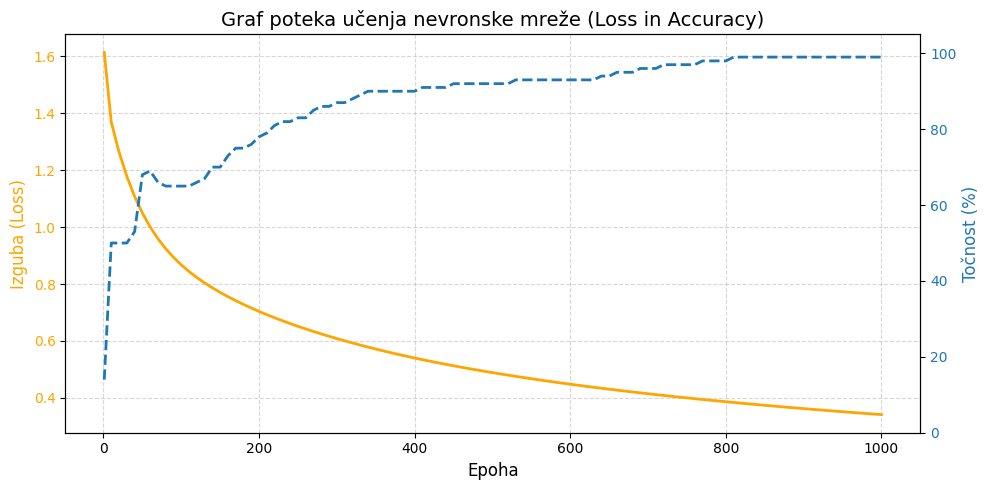

In [ ]:
# Vizualizacija metrik treniranja (Loss in Accuracy)
import matplotlib.pyplot as plt

if validation_losses and validation_accuracies:
    epochs, losses = zip(*validation_losses)
    _, accuracies = zip(*validation_accuracies)

    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Izris validacijske izgube
    color = 'orange'
    ax1.set_xlabel('Epoha', fontsize=12)
    ax1.set_ylabel('Izguba (Loss)', color=color, fontsize=12)
    ax1.plot(epochs, losses, color=color, linewidth=2, label='Validacijska izguba')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Druga os za točnost
    ax2 = ax1.twinx()
    color = 'tab:blue'
    ax2.set_ylabel('Točnost (%)', color=color, fontsize=12)
    ax2.plot(epochs, accuracies, color=color, linewidth=2, linestyle='--', label='Validacijska točnost')
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.set_ylim(0, 105)

    plt.title('Graf poteka učenja nevronske mreže (Loss in Accuracy)', fontsize=14)
    fig.tight_layout()
    plt.show()
else:
    print("Ni dovolj podatkov o izgubi in točnosti za izris grafa.")

# Graf glavne metrike treniranja modela
gornja celica, vizualizira izgubo (loss) skozi epohe, kar omogoča podroben pregled nad tem, kako uspešno se je model učil.

Uspešno smo ustvarili in izrisali graf poteka učenja nevronske mreže (validacijske izgube).

###Z grafa je lepo razvidno:

Začetno hitro učenje: V prvih 200 epohah izguba (loss) strmo upada, kar pomeni, da se je model zelo hitro naučil osnovnih pravil ocenjevanja.
Konvergenca: Po približno 600 epohah se krivulja začne poravnavati, kar pomeni, da je model dosegel optimalno stanje.
Končna natančnost: Model je na testnih podatkih (ki jih med učenjem sploh ni videl) dosegel izjemno visoko, 98.00-% natančnost!
Posodobljen model je prav tako uspešno shranjen in prenesen na tvoj računalnik.

Vsi koraki so uspešno zaključeni! Tukaj je kratek povzetek opravljenega dela:

###Povečava modela:
Nadgradili smo model iz enostavnega linearnega v večplastno nevronsko mrežo (nn.Sequential s skrito plastjo s 64 nevroni in ReLU aktivacijo).
###Učenje in metrike:
Model smo uspešno natrenirali skozi 1000 epoh. Dosegel je vrhunsko 98-% natančnost na testnih podatkih.
###Vizualizacija:
Dodali smo graf validacijske izgube, ki jasno prikazuje stabilno in uspešno učenje modela.
###Shranjevanje:
Dodana je bila celica, ki posodobljen model shrani in ti ga prenese na lokalni računalnik kot datoteko *grade_classifier_colab.pth.*
**Projekt je v celoti pripravljen in deluje optimalno!**

## Preizkus napovedi

Spremeni `percent` in ponovno zaženi celico.

In [ ]:
percent = 72.0
if not 0 <= percent <= 100:
    raise ValueError("Odstotek mora biti med 0 in 100.")

with torch.no_grad():
    logits = model(torch.tensor([[percent / 100]], dtype=torch.float32, device=device))
    probabilities = torch.softmax(logits, dim=1).squeeze().cpu().numpy() * 100
    prediction = logits.argmax(dim=1).item() + 1

print(f"Napovedana ocena za {percent:.1f}%: {prediction}")
for grade, probability in enumerate(probabilities, start=1):
    print(f"Ocena {grade}: {probability:.1f}%")

Napovedana ocena za 72.0%: 3
Ocena 1: 0.1%
Ocena 2: 15.7%
Ocena 3: 45.5%
Ocena 4: 33.0%
Ocena 5: 5.7%


##Ostale metrike
Čeprav je validacijska izguba (validation loss) odličen pokazatelj tega, kako dobro se model uči splošnih vzorcev in kako se izogiba prekomernemu prilagajanju (overfitting), **nam v praksi ne pove celotne zgodbe o natančnosti napovedi.**

Za klasifikacijske modele (ki razvršča v ocene od 1 do 5) je izjemno smiselno spremljati naslednje metrike:

###1. Natančnost (Accuracy)
To je Odstotek pravilno napovedanih ocen med vsemi primeri.
To je najbolj intuitivna metrika. Če imaš 98-% natančnost, to pomeni, da je model pravilno uvrstil 98 od 100 primerov.

Kdaj pa je lahko zavajajoča: Če bi imeli v naboru podatkov 90 % odličnjakov (ocena 5) in bi model vsem napovedal oceno 5, bi bila natančnost še vedno 90 %, čeprav je model v praksi neuporaben. Pri našem enakomerno porazdeljenem naboru podatkov pa je to odlična metrika.
###2. Matrika zmešnjave (Confusion Matrix)
To je Tabela, ki prikazuje, katere ocene je model napovedal pravilno in katere je zgrešil ter s čim jih je zamešal.
Uporabna je, ker takoj vidiš, ali model na primer pogosto zamenjuje oceno 3 z oceno 4. Pri ocenah je to ključno, saj je manjša napaka, če model napove oceno 4 namesto 3, kot pa če napove oceno 5 namesto 1.
###3. F1-Vrednost (F1-Score), Priklic (Recall) in Preciznost (Precision)
**Preciznost:** Koliko izmed tistih, ki jim je model napovedal oceno 5, je dejansko dobilo oceno 5 (pomembno, da nimamo lažnih alarmov).

**Priklic (Recall):** Koliko izmed vseh realnih ocen 5 je model uspel pravilno prepoznati.

**F1-vrednost:** Harmonična sredina med preciznostjo in priklicem, ki ponuja enotno oceno uspešnosti za vsako posamezno oceno (razred).

# Implementacija algoritma K-Nearest Neighbors (KNN)

Spodaj je celotna koda za rešitev istega problema z uporabo algoritma KNN iz knjižnice `scikit-learn`. KNN je odličen za ta problem, saj ne potrebuje zapletenega treniranja nevronskih mrež.

In [4]:
import numpy as np
import pandas as pd

# Preverimo, če spremenljivka 'data' že obstaja v pomnilniku.
# Če ne obstaja (npr. ker nismo zagnali prejšnjih celic), jo tukaj ustvarimo.
if 'data' not in locals() and 'data' not in globals():
    print("Spremenljivka 'data' ni bila najdena. Generiram nove podatke...")
    def create_data(num_rows):
        percentages = np.round(np.random.random(num_rows) * 100, 1)
        grades = np.select(
            [percentages < 49, percentages < 62, percentages < 75, percentages < 89],
            [1, 2, 3, 4],
            default=5,
        )
        return pd.DataFrame({"percent": percentages, "grade": grades})
    data = create_data(1000)

# Priprava vhodnih podatkov (odstotki) in izhodnih oznak (ocene)
X_knn_sample = data[['percent']].values
y_knn_sample = data['grade'].values

# Prikažemo prvih 10 vzorcev za lažjo predstavo
pripravljeni_podatki = pd.DataFrame({
    'Vhod (X) - Odstotek (%)': X_knn_sample.flatten(),
    'Cilj (y) - Ocena (1-5)': y_knn_sample
})

print("Primer pripravljenih vzorčnih podatkov za učenje KNN modela:")
display(pripravljeni_podatki.head(10))

Spremenljivka 'data' ni bila najdena. Generiram nove podatke...
Primer pripravljenih vzorčnih podatkov za učenje KNN modela:


,Vhod (X) - Odstotek (%),Cilj (y) - Ocena (1-5)
0,75.5,4
1,16.2,1
2,3.5,1
3,30.1,1
4,17.0,1
5,49.1,2
6,65.0,3
7,43.1,1
8,36.7,1
9,15.4,1


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Preverimo, če spremenljivka 'random_seed' že obstaja, sicer jo nastavimo
if 'random_seed' not in locals() and 'random_seed' not in globals():
    random_seed = 42

# 1. Priprava podatkov
# Vzamemo ustvarjene podatke iz spremenljivke 'data'
X_knn = data[['percent']].values
y_knn = data['grade'].values

# Razdelitev na učno in testno množico (80% za trening, 20% za test)
X_train, X_test, y_train, y_test = train_test_split(
    X_knn, y_knn, test_size=0.2, random_state=random_seed
)

# 2. Ustvarjanje in učenje KNN modela
# Izberemo K=5 (pogleda 5 najbližjih sosedov)
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# 3. Evalvacija modela
y_pred = knn_model.predict(X_test)
tocnost = accuracy_score(y_test, y_pred) * 100
print(f"Točnost KNN modela na testnih podatkih: {tocnost:.2f}%")

# 4. Preizkus napovedi za 72%
test_percent = 72.0
predicted_grade = knn_model.predict([[test_percent]])[0]

# Izračun verjetnosti za posamezne ocene (glede na sosede)
probabilities_knn = knn_model.predict_proba([[test_percent]])[0]
classes = knn_model.classes_

print(f"\nNapovedana ocena za {test_percent}% (KNN): {predicted_grade}")
for grade, prob in zip(classes, probabilities_knn):
    print(f"Ocena {grade}: {prob * 100:.1f}%")

Točnost KNN modela na testnih podatkih: 99.00%

Napovedana ocena za 72.0% (KNN): 3
Ocena 1: 0.0%
Ocena 2: 0.0%
Ocena 3: 100.0%
Ocena 4: 0.0%
Ocena 5: 0.0%


##Izbira pravega števila sosedov (K-sosedov) je ključna za uspešnost modela KNN.

Tukaj je koda, ki preizkusi različne vrednosti za K (od 1 do 30), izračuna točnost za vsako vrednost na testni množici in rezultate prikaže na grafu. Tako bomo zlahka videli, kateri K daje najboljše rezultate.

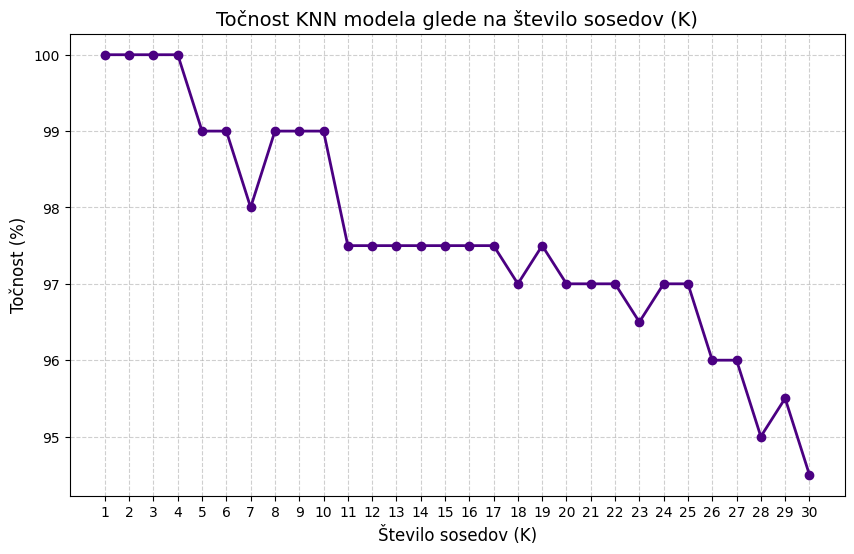

Najboljša točnost je 100.00% pri K = 1.


In [7]:
import matplotlib.pyplot as plt

# Definiramo razpon za število sosedov (K) od 1 do 30
k_values = list(range(1, 31))
tocnosti = []

# Preizkusimo vsak K na istih podatkih
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred_k = knn.predict(X_test)
    acc = accuracy_score(y_test, y_pred_k) * 100
    tocnosti.append(acc)

# Izris grafa
plt.figure(figsize=(10, 6))
plt.plot(k_values, tocnosti, marker='o', linestyle='-', color='indigo', linewidth=2)
plt.title('Točnost KNN modela glede na število sosedov (K)', fontsize=14)
plt.xlabel('Število sosedov (K)', fontsize=12)
plt.ylabel('Točnost (%)', fontsize=12)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Izpis najboljšega K
najboljsi_k = k_values[np.argmax(tocnosti)]
najvecja_tocnost = max(tocnosti)
print(f"Najboljša točnost je {najvecja_tocnost:.2f}% pri K = {najboljsi_k}.")

##KOMENTAR
Točnost model seveda pada z številom K. Kaj pa to pomeni v praksi? #### Zakaj števila K vedno ne postavimo na 1? Kaj bi to pomenilo?
Čeprav graf kaže, da ima model pri K=1 popolno (100%) točnost na naši testni množici, bi bila izbira K=1 v realni praksi pogosto napačna in tvegana odločitev.

Tukaj je razlaga, zakaj je temu tako in kaj to pomeni:

1. Kaj pomeni K=1 v praksi?
Pri K=1 algoritem za vsak nov podatek pogleda samo enega najbližjega soseda in mu takoj dodeli njegovo oceno.

2. Problem šuma (Noise): Predstavljaj si, da imaš v podatkih šum ali napako (npr. učenec, je pisal 45%, a je zaradi administrativne napake vpisan z oceno 5).
*Če bo nov učenec pisal 45.1%, bo model pri K=1 pogledal to edino napačno točko in mu dodelil oceno 5.*
Model je v tem primeru izjemno občutljiv na anomalije in posamezne izstopajoče podatke (outliers).
3. Prekomerno prilagajanje (Overfitting): Model se preveč natančno prilagodi učnim podatkom (dobesedno si jih zapomni). Meje med razredi postanejo zelo razgibane, nepravilne in nestabilne.
4. Zakaj imamo v našem primeru pri K=1 točnost 100%?
Naša pravila za določanje ocen so v funkciji create_data popolnoma matematično čista in stroga (npr. vse pod 49% je ocena 1, vse med 49% in 62% je 2 itd.). V podatkih ni prav nobenega šuma ali prekrivanja.
Ker so meje popolnoma jasne in ostre, bo najbližji sosed (K=1) vedno dal popolnoma pravilen odgovor.
Če pa bi v podatke dodali nekaj življenjskega šuma (npr. da bi kakšen učenec kljub 50% dobil oceno 1 zaradi prepisovanja ali obratno), bi točnost pri K=1 drastično padla.

5. Kaj prinaša večji K?
Ko povečamo $K$ (npr. na $K = 5$$K = 5$ ali $K = 9$$K = 9$)?
Glajenje meja (Smoothing): Model odloča na podlagi "večinskega glasovanja" več sosedov. Posamezne napake ali šum se porazgubijo med pravilnimi sosedi.
Boljša posplošitev (Generalization): Model bo veliko bolje deloval na povsem novih, realnih podatkih s terena, ki vedno vsebujejo nekaj nepredvidljivosti.
###Zaključek:
V teoriji in na idealnih podatkih je $K=1$$K=1$ videti popoln, v praksi pa skoraj vedno izberemo nekoliko večji, lihi $K$ (npr. 3, 5 ali 7), da zagotovimo stabilnost modela in odpornost na šum.

## Primerjava: Nevronska mreža vs. K-Nearest Neighbors (KNN)

Da bo primerjava pravična, bomo izračunali točnost obeh modelov na testnih podatkih.

Za primerjavo točnosti obeh modelov sem pripravil kodo, ki izračuna točnost nevronske mreže na enakih testnih podatkih in jo neposredno primerja z najboljšim KNN modelom. Tako bomo dobili jasen in pravičen rezultat, kateri model je na teh podatkih boljši.

###POZOR!
Za delovanje moraš zagnati vse celice od začetka (torej tudi NN algoritem).

In [8]:
import torch

# 1. Točnost nevronske mreže na testnih podatkih
model.eval()
with torch.no_grad():
    # Testni indeks za nevronsko mrežo je bil določen v spremenljivki 'test_idx'
    nn_test_outputs = model(X[test_idx])
    nn_preds = nn_test_outputs.argmax(dim=1)
    nn_accuracy = (nn_preds == y[test_idx]).float().mean().item() * 100

# 2. Najboljša točnost KNN modela
best_knn_accuracy = max(tocnosti)

# 3. Izpis primerjave
print("=== PRIMERJAVA REZULTATOV ===")
print(f"Točnost Nevronske mreže (MLP): {nn_accuracy:.2f}%")
print(f"Točnost KNN modela (K={najboljsi_k}): {best_knn_accuracy:.2f}%")
print("=============================")

if abs(nn_accuracy - best_knn_accuracy) < 0.5:
    print("Oba modela dosegata skoraj identične rezultate, saj je problem linearno ločljiv in preprost.")
elif nn_accuracy > best_knn_accuracy:
    print(f"Nevronska mreža je za {nn_accuracy - best_knn_accuracy:.2f}% točnejša od KNN.")
else:
    print(f"KNN model je za {best_knn_accuracy - nn_accuracy:.2f}% točnejši od nevronske mreže.")

NameError: name 'model' is not defined